In [269]:
import scanpy as sc
import numpy as np
import pandas as pd

from statsmodels.tsa.stattools import grangercausalitytests

In [270]:
sc.settings.verbosity = 0
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)

In [271]:
adata = sc.read("suberites_domuncula_cytotrace_SUB4.h5ad")

In [272]:
# sc.pp.neighbors(adata, n_pcs=350)
# sc.tl.umap(adata)

In [273]:
sc.tl.leiden(adata)

In [274]:
sc.tl.leiden(adata, key_added="leiden_res0_25", resolution=0.25)
sc.tl.leiden(adata, key_added="leiden_res0_5", resolution=0.5)
sc.tl.leiden(adata, key_added="leiden_res1", resolution=1.0)

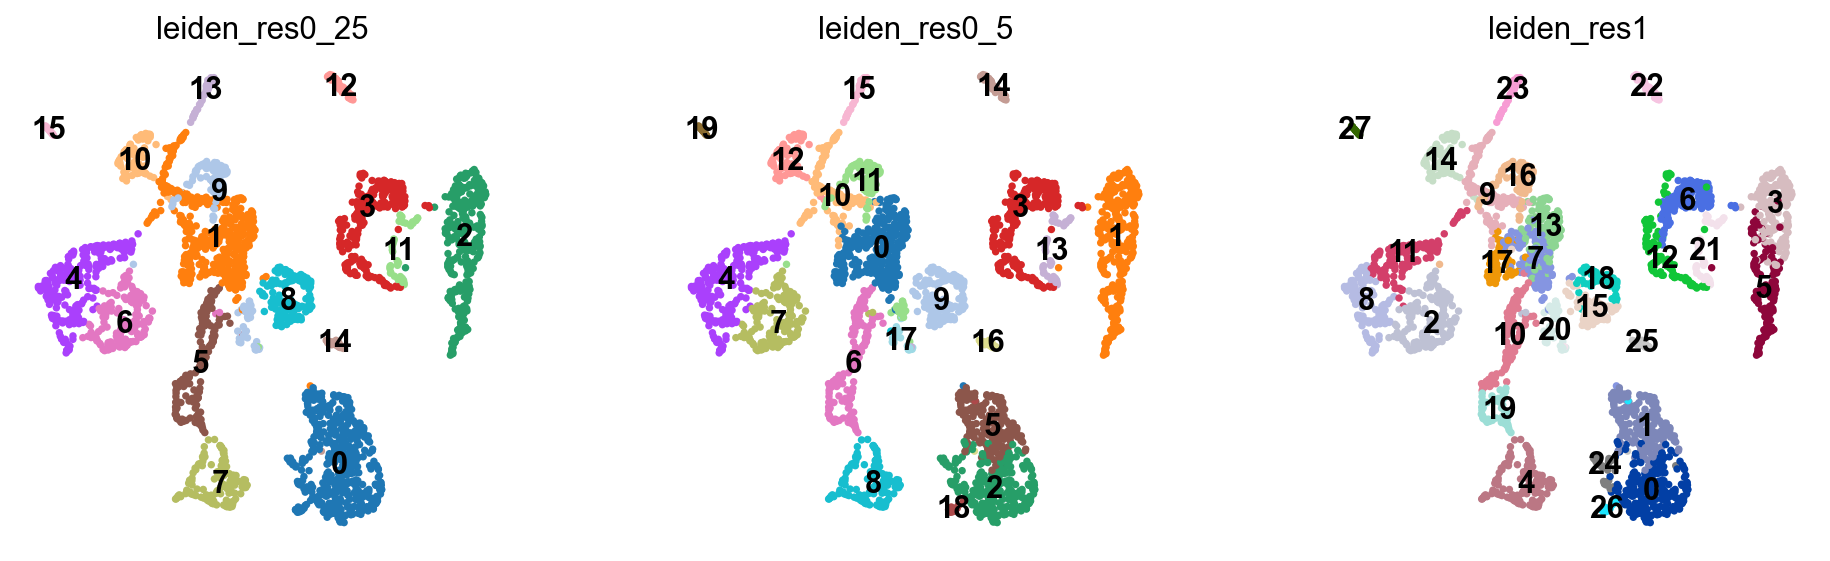

In [275]:
sc.pl.umap(
    adata,
    color=["leiden_res0_25", "leiden_res0_5", "leiden_res1"],
    legend_loc="on data",
)

In [31]:
adata.obs["leiden_res0_25"]

AAACCCAAGGACAGCT-1    4
AAACCCAAGGGTTTCT-1    0
AAACCCACAAATGGTA-1    2
AAACCCATCGAGAAGC-1    8
AAACCCATCTTGTTAC-1    4
                     ..
TTTGGTTGTGATGAAT-1    6
TTTGGTTGTTATAGCC-1    3
TTTGTTGAGAGAGTGA-1    4
TTTGTTGAGAGGTCGT-1    3
TTTGTTGAGGTAACTA-1    1
Name: leiden_res0_25, Length: 2662, dtype: category
Categories (15, object): ['0', '1', '2', '3', ..., '11', '12', '13', '14']

In [80]:
# cells x genes as a DataFrame
df = adata.to_df()

# align by index and add the labels column
df["clusters"] = adata.obs["clusters"].reindex(df.index)
df

,SUB4.g1,SUB4.g4,SUB4.g5,SUB4.g6,SUB4.g7,SUB4.g8,SUB4.g9,SUB4.g12,SUB4.g13,SUB4.g14,...,SUB4.g20341,SUB4.g20342,SUB4.g20343,SUB4.g20344,SUB4.g20345,SUB4.g20346,SUB4.g20347,SUB4.g20348,SUB4.g20349,clusters
AAACCCAAGGACAGCT-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.17745,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,3
AAACCCAAGGGTTTCT-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.21199,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0
AAACCCACAAATGGTA-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.46722,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,2
AAACCCATCGAGAAGC-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.26809,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,8
AAACCCATCTTGTTAC-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.25323,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGTTGTGATGAAT-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.56981,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,6
TTTGGTTGTTATAGCC-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.12447,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,4
TTTGTTGAGAGAGTGA-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.16200,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,3
TTTGTTGAGAGGTCGT-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.17448,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,4


In [81]:
import numpy as np
labels_array = adata.obs["clusters"].to_numpy()  # aligns with rows of adata.X
labels_array

array(['3', '0', '2', ..., '3', '4', '1'], shape=(2662,), dtype=object)

In [109]:
# align by index and add the labels column
df["ct_pseudotime"] = adata.obs["ct_pseudotime"].reindex(df.index)
df

,SUB4.g1,SUB4.g4,SUB4.g5,SUB4.g6,SUB4.g7,SUB4.g8,SUB4.g9,SUB4.g12,SUB4.g13,SUB4.g14,...,SUB4.g20342,SUB4.g20343,SUB4.g20344,SUB4.g20345,SUB4.g20346,SUB4.g20347,SUB4.g20348,SUB4.g20349,clusters,ct_pseudotime
AAACCCAAGGACAGCT-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.17745,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,3,0.81393
AAACCCAAGGGTTTCT-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.21199,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0,0.63327
AAACCCACAAATGGTA-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.46722,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,2,0.84476
AAACCCATCGAGAAGC-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.26809,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,8,0.63937
AAACCCATCTTGTTAC-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.25323,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,3,0.82187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGTTGTGATGAAT-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.56981,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,6,0.60169
TTTGGTTGTTATAGCC-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.12447,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,4,0.22981
TTTGTTGAGAGAGTGA-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.16200,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,3,0.81431
TTTGTTGAGAGGTCGT-1,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,-0.17448,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,4,0.20166


In [110]:
import numpy as np
labels_array_pseudotime = adata.obs["ct_pseudotime"].to_numpy()  # aligns with rows of adata.X
labels_array_pseudotime

array([0.81393343, 0.6332667 , 0.84476274, ..., 0.8143106 , 0.2016573 ,
       0.18307275], shape=(2662,), dtype=float32)

In [112]:
len(labels_array), len(labels_array_pseudotime)

(2662, 2662)

In [106]:
distances = ["cityblock", "cosine", "euclidean", "l1", "l2", "manhattan", "nan_euclidean"]

In [107]:
import scanpy as sc
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_samples, silhouette_score

for distance in distances:
    # 1) Make sure you have PCA (and Leiden labels)
    # if "X_pca" not in adata.obsm_keys():
        # sc.pp.scale(adata, max_value=10)       # optional but common
        # sc.tl.pca(adata, n_comps=50)

    labels_cat = adata.obs["clusters"].astype("category")
    labels = labels_cat.cat.codes.to_numpy()   # integers for sklearn
    X = adata.obsm["X_pca"]                    # (cells x PCs)

    # 2) Per-cell silhouette and overall silhouette
    cell_sil = silhouette_samples(X, labels, metric=distance)
    overall_sil = silhouette_score(X, labels, metric=distance)

    # 3) Store per-cell scores back on the AnnData
    adata.obs[f"silhouette_samples_{distance}"] = cell_sil
    adata.obs[f"silhouette_score_{distance}"] = overall_sil

    # 4) Aggregate per cluster (mean; you can also look at median)
    per_cluster_mean = (
        pd.Series(cell_sil, index=adata.obs_names)
        .groupby(labels_cat)
        .mean()
        .sort_values(ascending=False)
    )

    per_cluster_median = (
        pd.Series(cell_sil, index=adata.obs_names)
        .groupby(labels_cat)
        .median()
        .sort_values(ascending=False)
    )

    print(f"---------------- DISTANCE {distance} -------------")
    print(f"Overall silhouette: {overall_sil:.3f}")
    print("\nPer-cluster mean silhouette:")
    print(per_cluster_mean)
    print("\nPer-cluster median silhouette:")
    print(per_cluster_median)

/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2832221527.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(labels_cat)
/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2832221527.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(labels_cat)
/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2832221527.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warnin

---------------- DISTANCE cityblock -------------
Overall silhouette: 0.209

Per-cluster mean silhouette:
clusters
14   0.91173
13   0.64321
11   0.40360
12   0.39856
3    0.35787
7    0.27908
8    0.23936
2    0.22479
6    0.21591
4    0.17981
0    0.17447
9    0.16251
5    0.12917
1    0.09120
10   0.01454
dtype: float64

Per-cluster median silhouette:
clusters
14   0.92504
13   0.64783
11   0.42402
12   0.41996
3    0.38585
7    0.29823
8    0.26375
2    0.24300
6    0.22565
4    0.21101
0    0.19504
9    0.17892
5    0.15091
1    0.11585
10   0.01718
dtype: float64
---------------- DISTANCE cosine -------------
Overall silhouette: 0.519

Per-cluster mean silhouette:
clusters
14    0.99146
13    0.93427
11    0.85501
12    0.84042
8     0.74546
0     0.62782
3     0.59224
7     0.57811
5     0.57157
2     0.53842
4     0.53800
6     0.52174
9     0.40054
1     0.20173
10   -0.11250
dtype: float32

Per-cluster median silhouette:
clusters
14    0.99401
13    0.94155
12    0.88051
11  

/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2832221527.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(labels_cat)
/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2832221527.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(labels_cat)
/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2832221527.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warnin

---------------- DISTANCE l1 -------------
Overall silhouette: 0.209

Per-cluster mean silhouette:
clusters
14   0.91173
13   0.64321
11   0.40360
12   0.39856
3    0.35787
7    0.27908
8    0.23936
2    0.22479
6    0.21591
4    0.17981
0    0.17447
9    0.16251
5    0.12917
1    0.09120
10   0.01454
dtype: float64

Per-cluster median silhouette:
clusters
14   0.92504
13   0.64783
11   0.42402
12   0.41996
3    0.38585
7    0.29823
8    0.26375
2    0.24300
6    0.22565
4    0.21101
0    0.19504
9    0.17892
5    0.15091
1    0.11585
10   0.01718
dtype: float64
---------------- DISTANCE l2 -------------
Overall silhouette: 0.373

Per-cluster mean silhouette:
clusters
14   0.92176
13   0.76728
11   0.65799
12   0.63805
7    0.48231
8    0.48023
0    0.42604
3    0.41273
6    0.35456
2    0.31422
9    0.31366
4    0.30857
1    0.29385
5    0.27762
10   0.03412
dtype: float32

Per-cluster median silhouette:
clusters
14   0.93282
13   0.78460
12   0.68134
11   0.67238
7    0.52128
8    0.

/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2832221527.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(labels_cat)
/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2832221527.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(labels_cat)


---------------- DISTANCE manhattan -------------
Overall silhouette: 0.209

Per-cluster mean silhouette:
clusters
14   0.91173
13   0.64321
11   0.40360
12   0.39856
3    0.35787
7    0.27908
8    0.23936
2    0.22479
6    0.21591
4    0.17981
0    0.17447
9    0.16251
5    0.12917
1    0.09120
10   0.01454
dtype: float64

Per-cluster median silhouette:
clusters
14   0.92504
13   0.64783
11   0.42402
12   0.41996
3    0.38585
7    0.29823
8    0.26375
2    0.24300
6    0.22565
4    0.21101
0    0.19504
9    0.17892
5    0.15091
1    0.11585
10   0.01718
dtype: float64
---------------- DISTANCE nan_euclidean -------------
Overall silhouette: 0.373

Per-cluster mean silhouette:
clusters
14   0.92176
13   0.76728
11   0.65799
12   0.63805
7    0.48231
8    0.48023
0    0.42604
3    0.41273
6    0.35456
2    0.31422
9    0.31366
4    0.30857
1    0.29385
5    0.27762
10   0.03412
dtype: float32

Per-cluster median silhouette:
clusters
14   0.93282
13   0.78460
12   0.68134
11   0.67238
7 

/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2832221527.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(labels_cat)
/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2832221527.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(labels_cat)


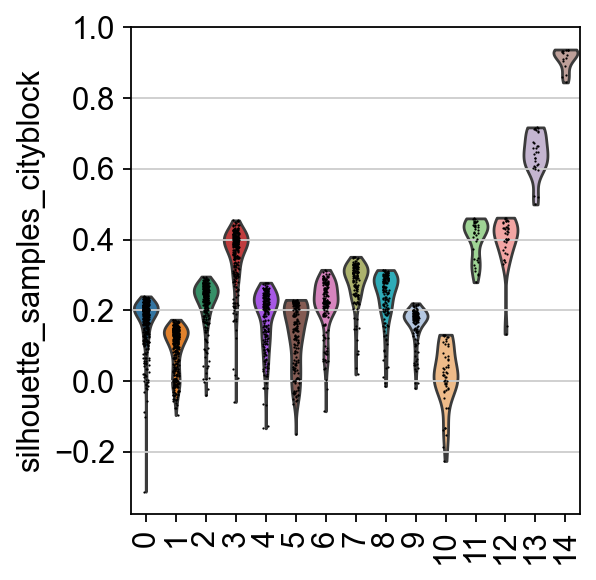

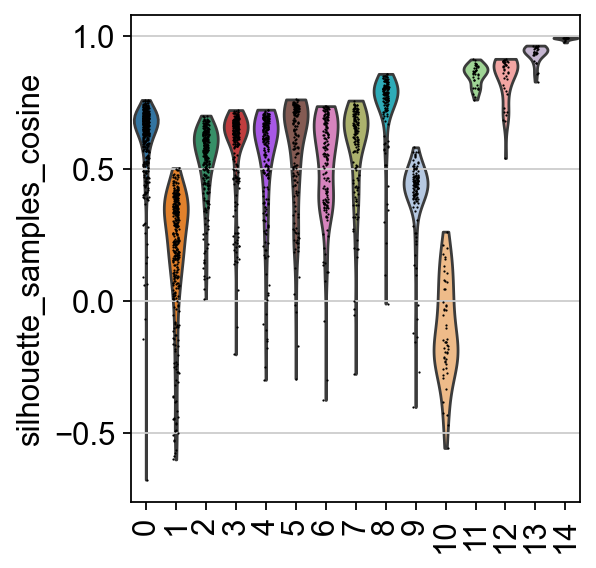

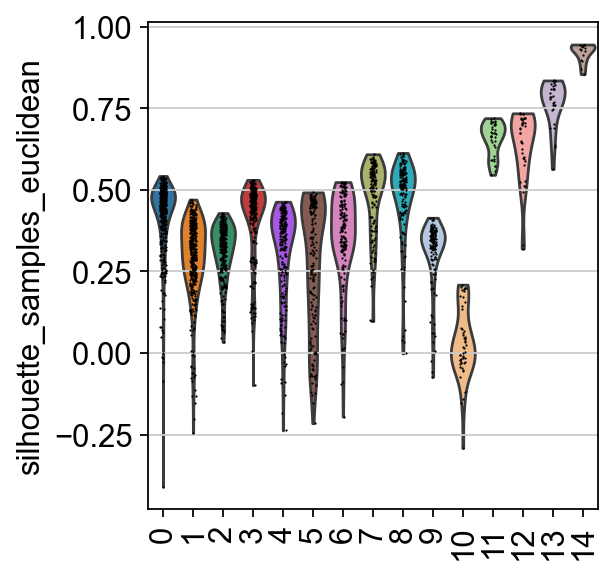

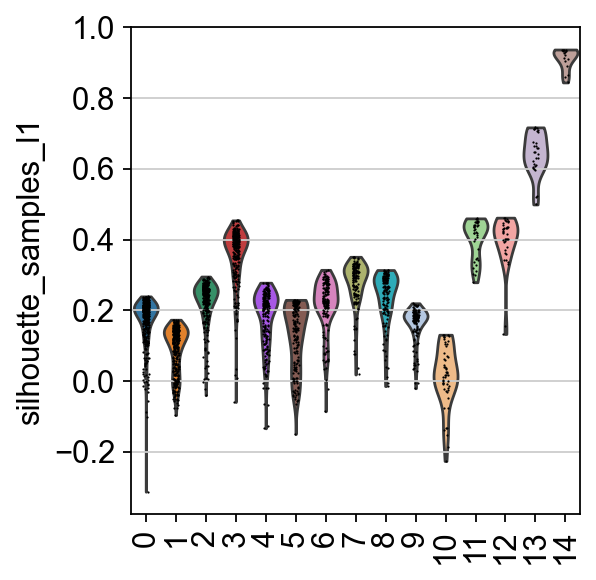

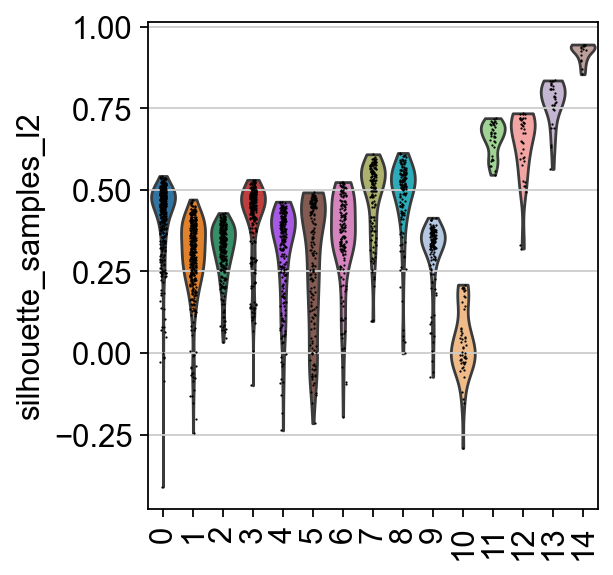

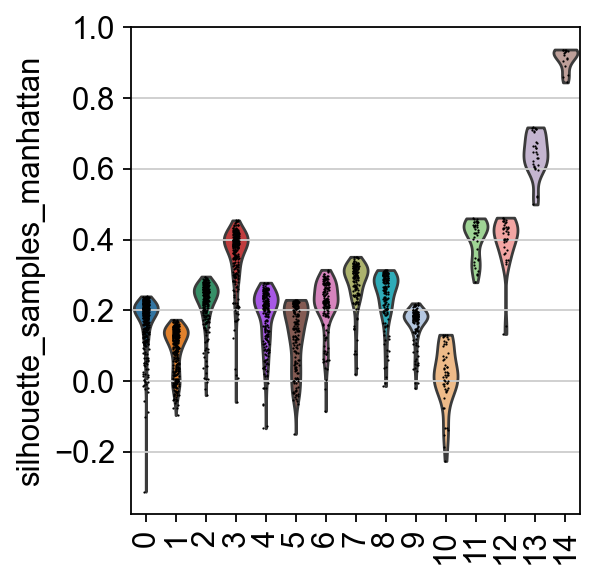

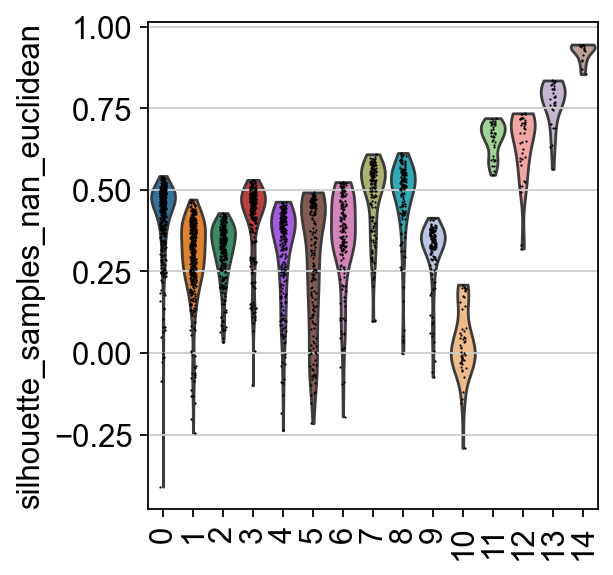

In [100]:
for distance in distances:
    sc.pl.violin(adata, keys=f"silhouette_samples_{distance}", groupby="clusters", rotation=90)

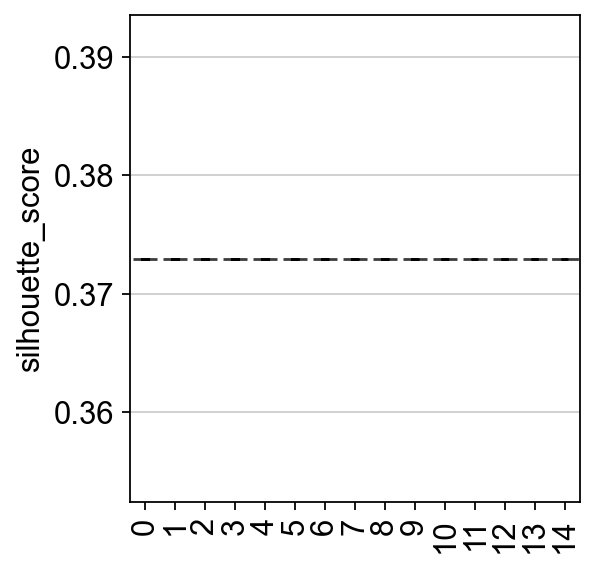

In [85]:
sc.pl.violin(adata, keys="silhouette_score", groupby="clusters", rotation=90)

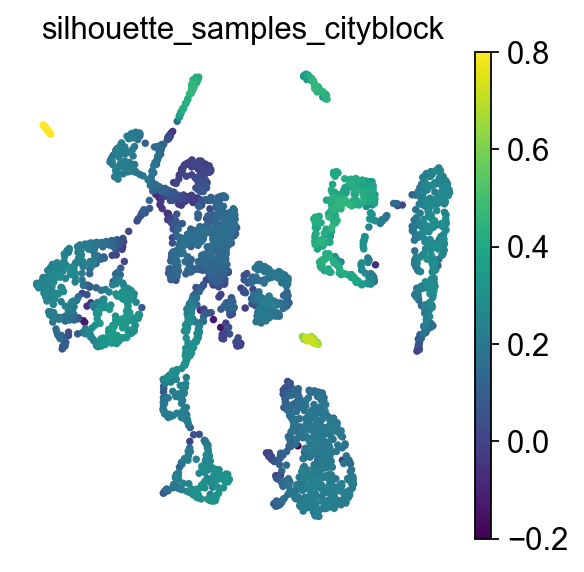

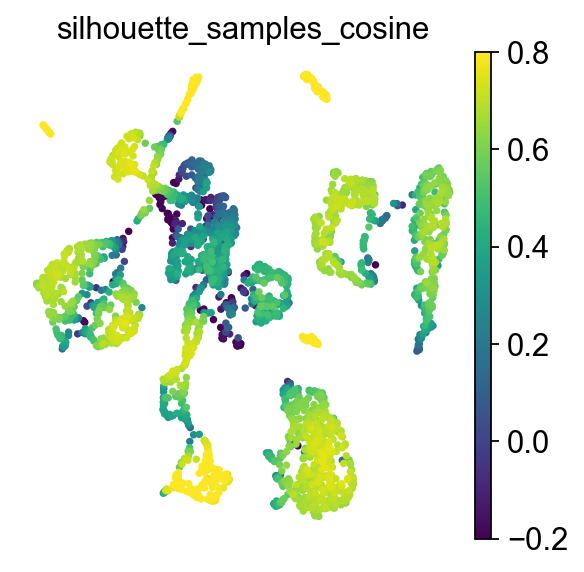

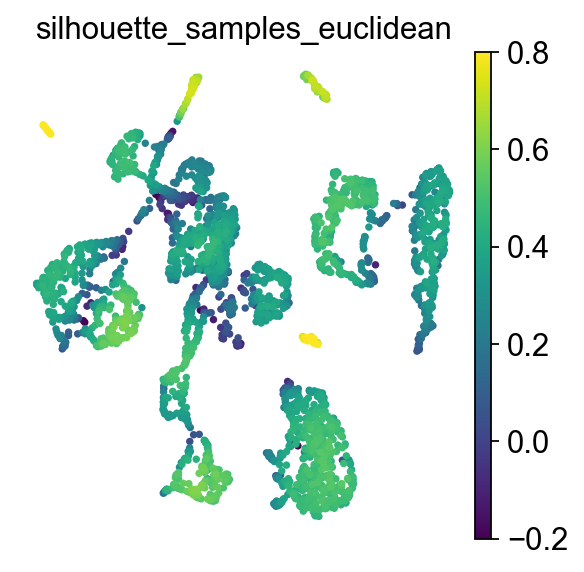

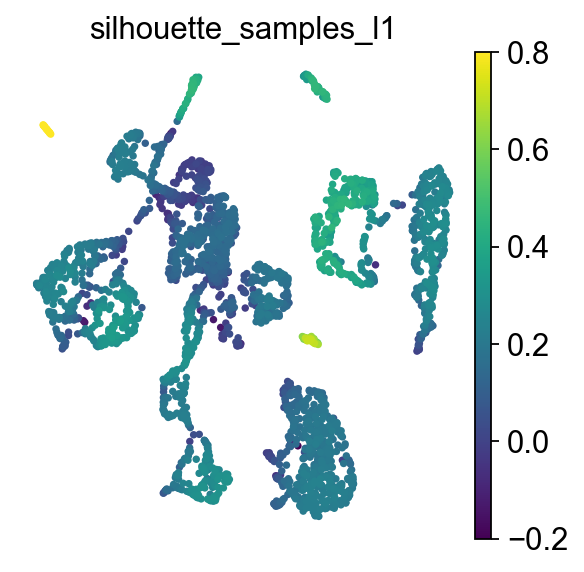

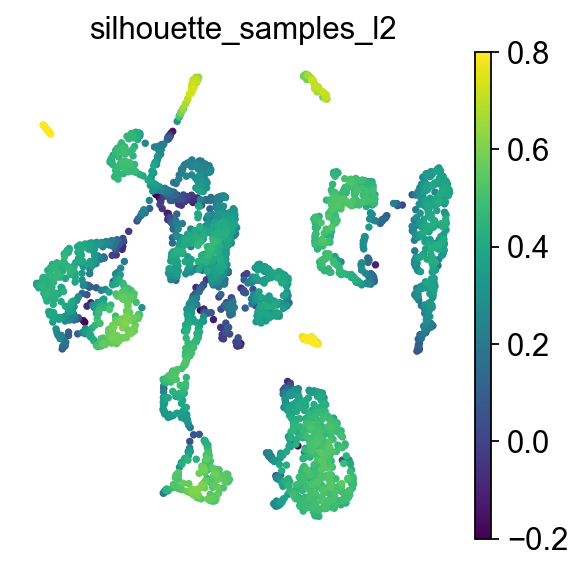

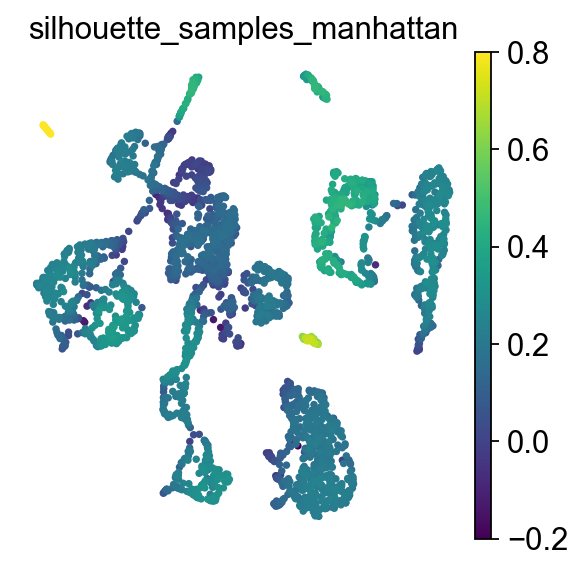

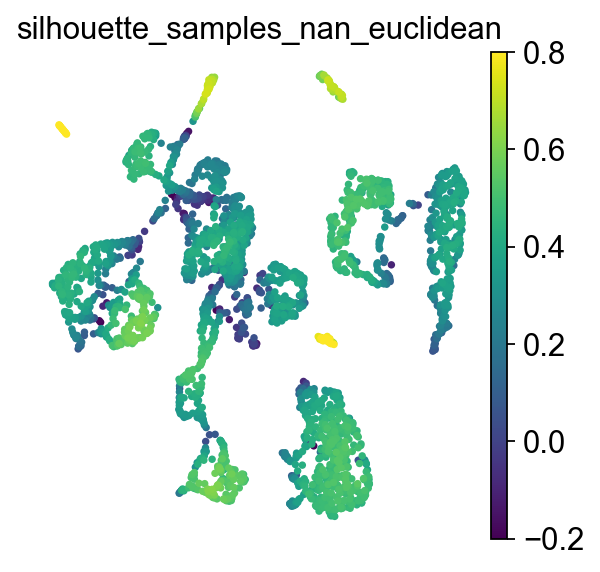

In [103]:
for distance in distances:
    sc.pl.umap(adata, vmin=-0.2, vmax=0.8, color=[f"silhouette_samples_{distance}"])

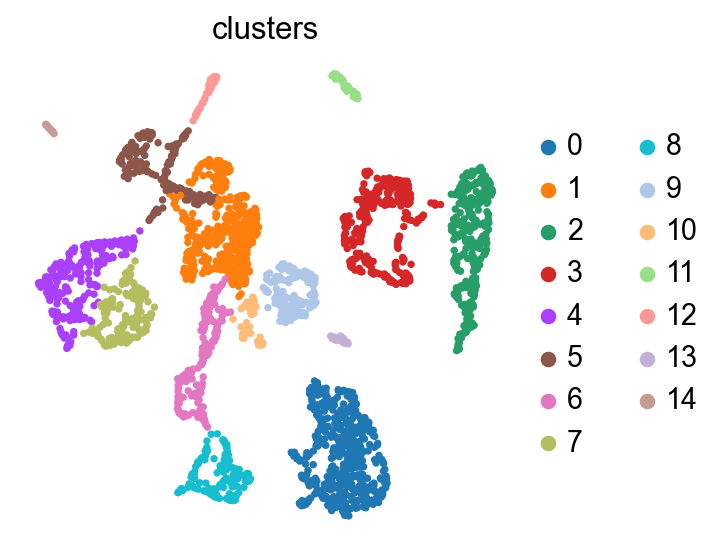

In [93]:
sc.pl.umap(adata, color=["clusters"])

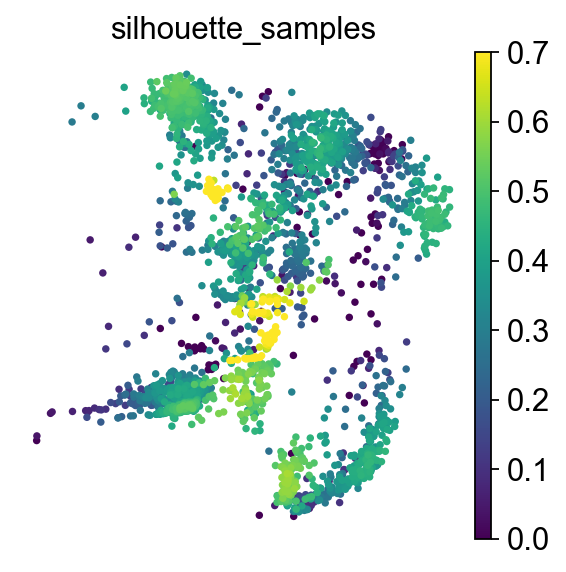

In [96]:
sc.pl.pca(adata, vmin=0, vmax=0.7, color="silhouette_samples")

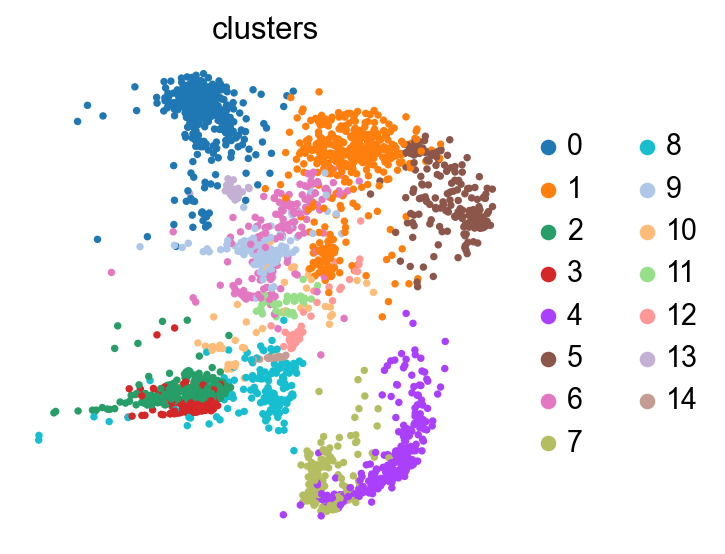

In [90]:
sc.pl.pca(adata, color="clusters")

In [104]:
labels = [1, 5]  # transition, stammzelle

In [105]:
labels_cluster = [2, 3]  # unify

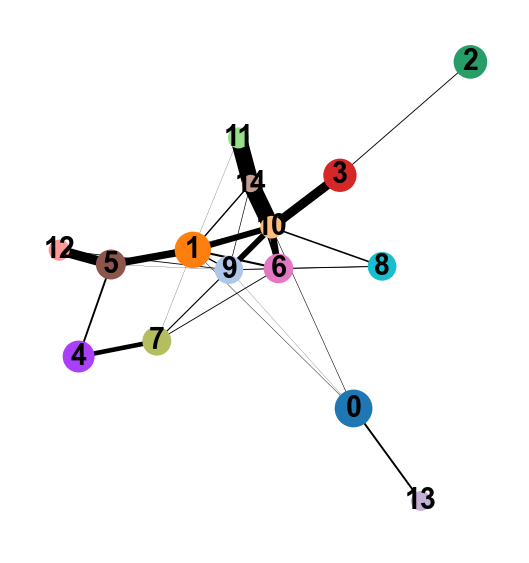

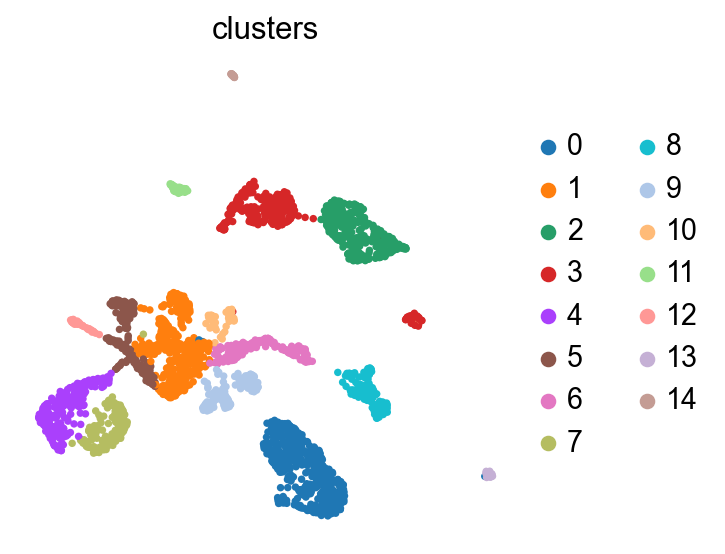

In [108]:
# assuming neighbors + Leiden already computed
sc.tl.paga(adata, groups="clusters")           # or your preferred cluster key
sc.pl.paga(adata, color=["clusters"])           # graph of cluster connectivities

# Use PAGA init for embeddings so paths are respected
sc.tl.umap(adata, init_pos="paga")            # optional: re-compute UMAP
sc.pl.umap(adata, color=["clusters"])

In [117]:
adata.obs["ct_pseudotime"]

AAACCCAAGGACAGCT-1   0.81393
AAACCCAAGGGTTTCT-1   0.63327
AAACCCACAAATGGTA-1   0.84476
AAACCCATCGAGAAGC-1   0.63937
AAACCCATCTTGTTAC-1   0.82187
                       ...  
TTTGGTTGTGATGAAT-1   0.60169
TTTGGTTGTTATAGCC-1   0.22981
TTTGTTGAGAGAGTGA-1   0.81431
TTTGTTGAGAGGTCGT-1   0.20166
TTTGTTGAGGTAACTA-1   0.18307
Name: ct_pseudotime, Length: 2662, dtype: float32

/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/2702257631.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('clusters')['ct_pseudotime']


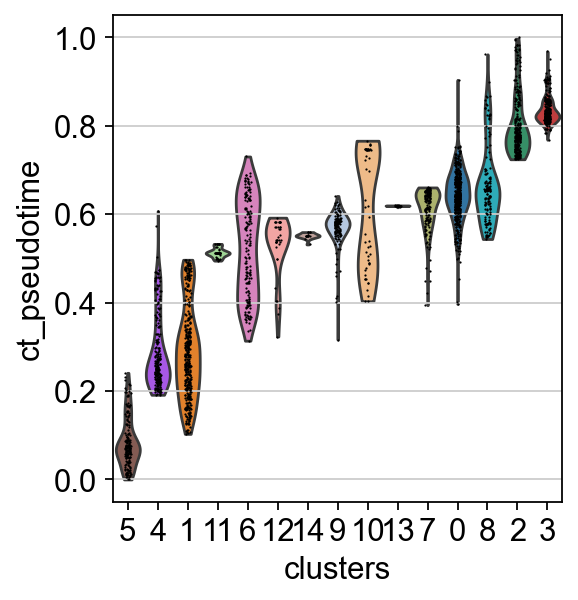

In [119]:
# Optional: order clusters by median pseudotime for a nicer left→right trend
order = (
    adata.obs
    .groupby('clusters')['ct_pseudotime']
    .median()
    .sort_values()
    .index
    .tolist()
)

sc.pl.violin(
    adata,
    keys='ct_pseudotime',
    groupby='clusters',
    order=order,         # remove if you want the default order
    stripplot=True,      # show individual cells
    jitter=0.1
    # save='_ct_pseudotime_by_cluster.png'  # uncomment to save; see sc.settings.figdir
)


In [126]:
cluster_order = adata.obs.groupby("clusters")["ct_pseudotime"].mean().sort_values()
print(cluster_order)

clusters
5    0.08293
4    0.28778
1    0.28890
11   0.51325
6    0.52399
12   0.52909
14   0.55137
9    0.56811
10   0.61070
7    0.61109
13   0.61909
0    0.64282
8    0.66397
2    0.80253
3    0.83596
Name: ct_pseudotime, dtype: float32


/var/folders/75/7kkbnyxd3d76jwmks2k8dy700000gn/T/ipykernel_18465/3124386902.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_order = adata.obs.groupby("clusters")["ct_pseudotime"].mean().sort_values()


In [127]:
pt = adata.obs["ct_pseudotime"].to_numpy()
clusters = adata.obs["clusters"].astype(int)

n_bins = 40
bins = np.linspace(pt.min(), pt.max(), n_bins+1)
bin_id = np.digitize(pt, bins) - 1

# fraction of cells in each cluster per bin
df = pd.crosstab(bin_id, clusters, normalize="index").fillna(0)

# Granger test between cluster 3 and 7
data = df[[7,3]].to_numpy()  # column 0 = target (cluster7), col1 = predictor (cluster3)
res = grangercausalitytests(data, maxlag=3, verbose=False)
for lag, out in res.items():
    print(f"Lag {lag}: p={out[0]['ssr_ftest'][1]:.3g}")


Lag 1: p=0.642
Lag 2: p=0.841
Lag 3: p=0.962


/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions sh

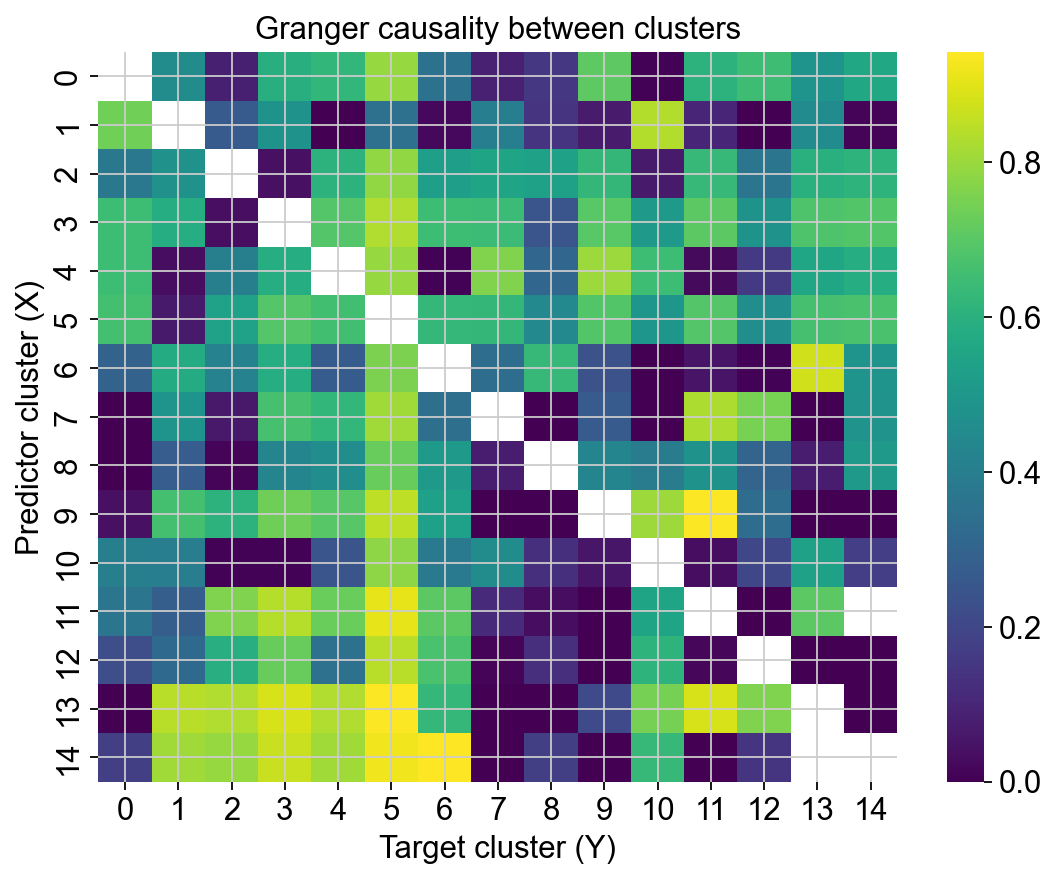

In [132]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import grangercausalitytests
import itertools

# --- Step 1: Bin pseudotime and compute cluster fractions per bin ---
pt = adata.obs["ct_pseudotime"].to_numpy()
clusters = adata.obs["clusters"].astype(int)

n_bins = 40  # adjust depending on dataset size
bins = np.linspace(pt.min(), pt.max(), n_bins+1)
bin_id = np.digitize(pt, bins) - 1

# fraction of cells per cluster per pseudotime bin
df = pd.crosstab(bin_id, clusters, normalize="index").fillna(0)

# --- Step 2: Compute Granger causality p-values between all pairs ---
maxlag = 3
clusters_unique = sorted(df.columns)
pvals = pd.DataFrame(np.nan, index=clusters_unique, columns=clusters_unique)

for i, j in itertools.permutations(clusters_unique, 2):
    data = df[[j, i]].to_numpy()  # col0=target Y=j, col1=predictor X=i
    try:
        res = grangercausalitytests(data, maxlag=maxlag, verbose=False)
        # take minimum p-value across lags
        min_p = min(out[0]['ssr_ftest'][1] for out in res.values())
        pvals.loc[i, j] = min_p
    except Exception:
        # some pairs may fail if time series are too flat/constant
        continue

# --- Step 3: Inspect results ---
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(pvals.astype(float), cmap="viridis",
            xticklabels=True, yticklabels=True)
plt.title("Granger causality between clusters")
plt.xlabel("Target cluster (Y)")
plt.ylabel("Predictor cluster (X)")
plt.show()


In [130]:
pvals

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,NaN,0.45475,0.08163,0.59601,0.61879,0.79150,0.35440,0.08583,0.14996,0.70878,0.00531,0.60573,0.65024,0.48786,0.55948
1,0.73722,NaN,0.26611,0.47582,0.00030,0.34824,0.02127,0.39866,0.14251,0.06873,0.83234,0.09656,0.00006,0.45103,0.00906
2,0.37742,0.47314,NaN,0.03950,0.60635,0.78463,0.52465,0.55140,0.53541,0.62238,0.06601,0.63215,0.36696,0.59905,0.61037
3,0.64595,0.58350,0.03525,NaN,0.68940,0.83052,0.64394,0.64175,0.24496,0.69904,0.50744,0.70570,0.47973,0.67793,0.68752
4,0.64470,0.03092,0.40107,0.58424,NaN,0.79455,0.00595,0.76424,0.30658,0.80076,0.64710,0.02390,0.15604,0.55695,0.58354
5,0.66180,0.06362,0.54296,0.68871,0.65827,NaN,0.62629,0.62443,0.44402,0.68439,0.49373,0.69157,0.45729,0.66271,0.67266
6,0.29413,0.57516,0.41909,0.58413,0.27125,0.75765,NaN,0.33240,0.63168,0.23633,0.00149,0.05132,0.00427,0.87565,0.48670
7,0.00000,0.48884,0.06068,0.66304,0.62130,0.80653,0.34147,NaN,0.00022,0.26740,0.00186,0.82723,0.75031,0.00066,0.48268
8,0.00008,0.27362,0.01104,0.42780,0.45793,0.72453,0.50678,0.07385,NaN,0.42880,0.38929,0.48113,0.30146,0.07171,0.50502
9,0.04031,0.66024,0.60474,0.73239,0.69492,0.84766,0.53158,0.00000,0.00009,NaN,0.80341,0.93796,0.33162,0.00000,0.00102


/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions sh

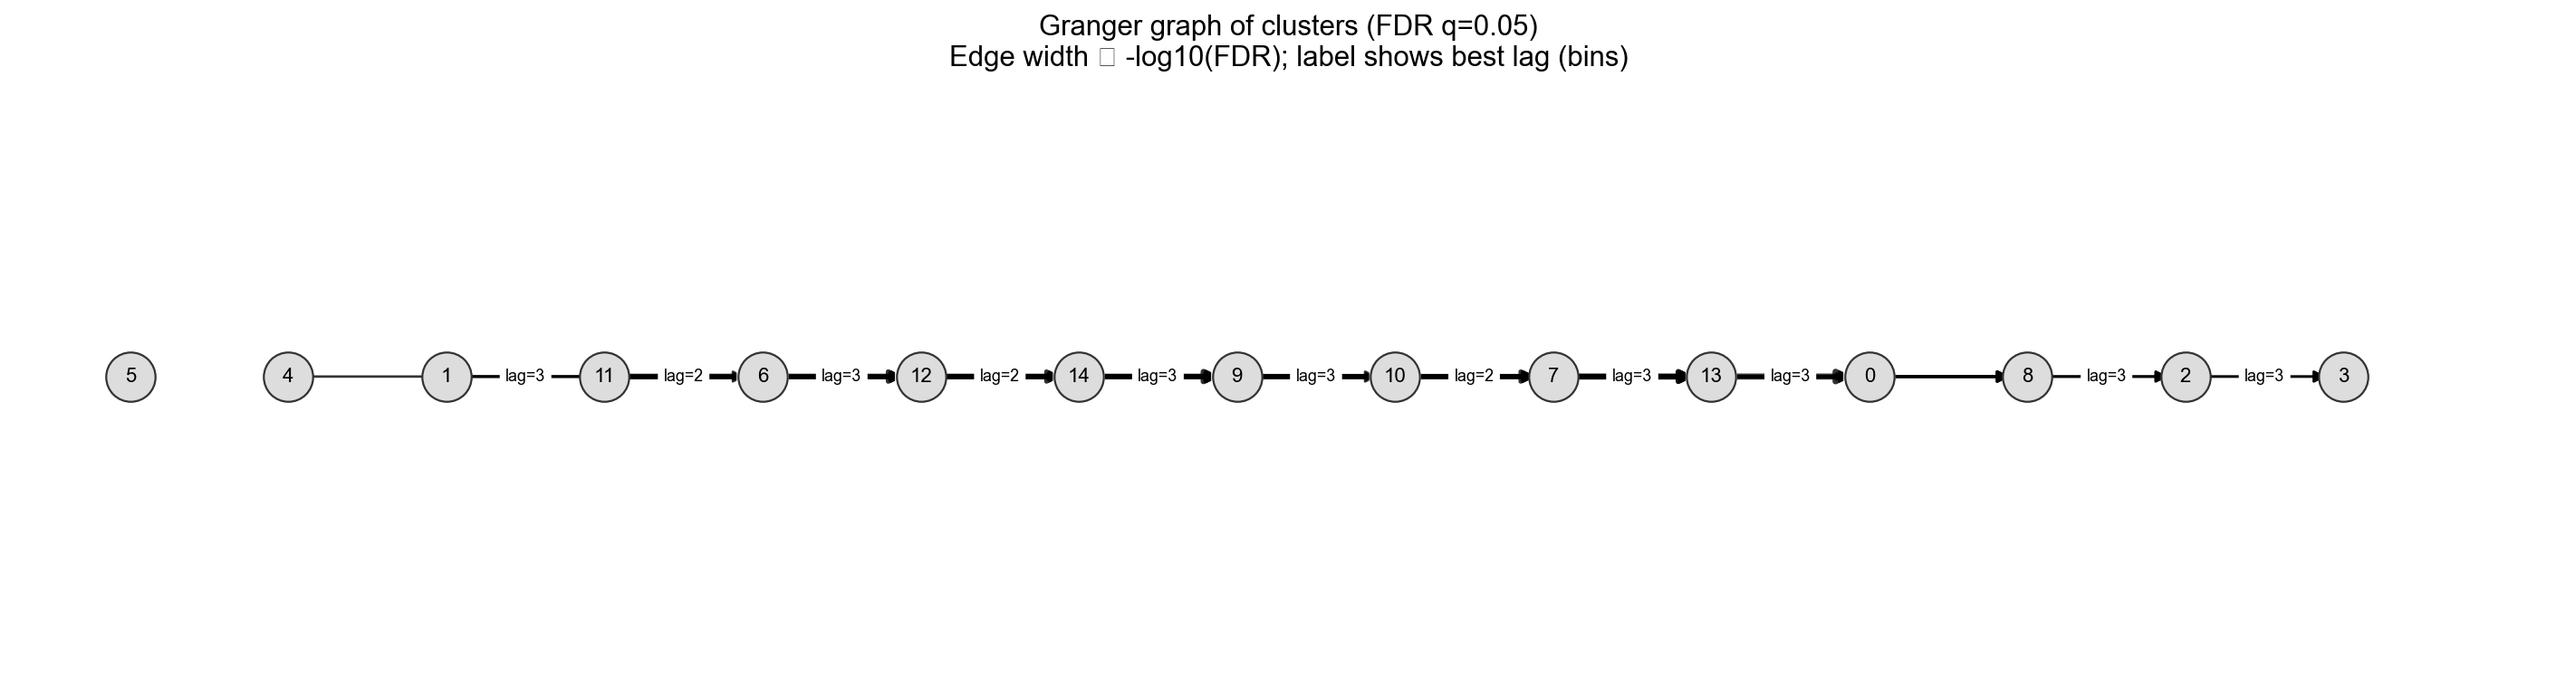

,src,dst,p,lag,p_adj,significant,weight
53,7,0,0.00000,2,0.00000,True,13.51254
79,11,9,0.00000,3,0.00000,True,12.54310
66,9,13,0.00000,2,0.00000,True,11.08804
90,12,13,0.00000,3,0.00000,True,10.39590
81,11,12,0.00000,1,0.00000,True,9.61291
91,12,14,0.00000,2,0.00000,True,9.06308
63,9,7,0.00000,3,0.00000,True,9.06308
88,12,9,0.00000,3,0.00000,True,6.72515
101,14,9,0.00000,3,0.00001,True,5.01932
99,14,7,0.00002,3,0.00016,True,3.78423


In [134]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.stats.multitest import multipletests
import itertools

# --- Inputs you already have ---
pt = adata.obs["ct_pseudotime"].to_numpy()
clusters_cat = adata.obs["clusters"].astype(int)   # 0..14 (or whatever)
n_bins = 40
maxlag = 3
fdr_alpha = 0.05
enforce_temporal_direction = True  # set False to keep all directions

# --- 1) Bin pseudotime and compute cluster fractions per bin ---
bins = np.linspace(pt.min(), pt.max(), n_bins+1)
bin_id = np.digitize(pt, bins) - 1
df_frac = pd.crosstab(bin_id, clusters_cat, normalize="index").reindex(range(n_bins)).fillna(0)

# Mean pseudotime per cluster for optional direction sanity check
cluster_pt_mean = (
    pd.DataFrame({"pt": pt, "cl": clusters_cat})
    .groupby("cl")["pt"].mean()
)

clusters_unique = sorted(df_frac.columns)

# --- 2) Granger tests for all ordered pairs ---
records = []
for i, j in itertools.permutations(clusters_unique, 2):
    # Optional: only test plausible temporal direction
    if enforce_temporal_direction and cluster_pt_mean[i] >= cluster_pt_mean[j]:
        continue

    # target Y = cluster j fraction; predictor X = cluster i fraction
    data = df_frac[[j, i]].to_numpy()  # col0=Y, col1=X
    # guard against constant/near-constant series
    if np.isclose(data.var(axis=0), 0).any():
        continue

    try:
        res = grangercausalitytests(data, maxlag=maxlag, verbose=False)
        # Pull the p-values for the SSR F-test at each lag
        lag_pvals = {lag: out[0]['ssr_ftest'][1] for lag, out in res.items()}
        best_lag = min(lag_pvals, key=lag_pvals.get)
        best_p = lag_pvals[best_lag]
        records.append({"src": i, "dst": j, "p": best_p, "lag": best_lag})
    except Exception:
        # skip pairs that fail (e.g., too short series, singular design)
        continue

edges_df = pd.DataFrame(records)
if edges_df.empty:
    print("No valid Granger results (check binning, cluster sizes).")

# --- 3) Multiple-testing correction (FDR) ---
rej, p_adj, _, _ = multipletests(edges_df["p"].values, alpha=fdr_alpha, method="fdr_bh")
edges_df["p_adj"] = p_adj
edges_df["significant"] = rej

# Keep only significant edges
sig_edges = edges_df[edges_df["significant"]].copy()
sig_edges.sort_values("p_adj", inplace=True)

# --- 4) Build and visualize the directed graph ---
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
G.add_nodes_from(clusters_unique)
# Edge weight = significance score (larger = more significant)
sig_edges["weight"] = -np.log10(sig_edges["p_adj"].clip(lower=1e-300))
for _, r in sig_edges.iterrows():
    G.add_edge(int(r["src"]), int(r["dst"]),
               weight=float(r["weight"]),
               lag=int(r["lag"]),
               p_adj=float(r["p_adj"]))

# Layout: order by mean pseudotime along x-axis for readability
pos = {}
order = cluster_pt_mean.sort_values().index.tolist()
for k, cl in enumerate(order):
    pos[int(cl)] = (k, 0)

plt.figure(figsize=(1.2*len(order), 5))
# Node styling
nx.draw_networkx_nodes(G, pos, node_size=600, node_color="#dddddd", edgecolors="#333333")
nx.draw_networkx_labels(G, pos, font_size=10)

# Edge styling (width by significance; arrows on)
if G.number_of_edges() > 0:
    widths = [1 + 2*(G[u][v]['weight'] / (sig_edges['weight'].max() or 1.0)) for u, v in G.edges()]
    nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle='-|>', arrowsize=12, width=widths, alpha=0.8)

# Edge labels: show lag (bins)
edge_labels = {(u, v): f"lag={G[u][v]['lag']}" for u, v in G.edges()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

plt.title(f"Granger graph of clusters (FDR q={fdr_alpha})\nEdge width ∝ -log10(FDR); label shows best lag (bins)")
plt.axis("off")
plt.tight_layout()
plt.show()

# --- 5) Inspect the table of significant edges ---
sig_edges

In [154]:
adata.obs["silhouette_samples_euclidean"]

AAACCCAAGGACAGCT-1    0.46510
AAACCCAAGGGTTTCT-1    0.48878
AAACCCACAAATGGTA-1    0.35924
AAACCCATCGAGAAGC-1    0.51855
AAACCCATCTTGTTAC-1    0.34320
                       ...   
TTTGGTTGTGATGAAT-1    0.48702
TTTGGTTGTTATAGCC-1   -0.02848
TTTGTTGAGAGAGTGA-1    0.49375
TTTGTTGAGAGGTCGT-1    0.40287
TTTGTTGAGGTAACTA-1    0.37252
Name: silhouette_samples_euclidean, Length: 2662, dtype: float32

In [155]:
import pandas as pd
from scipy.stats import spearmanr, pearsonr

sil = adata.obs["silhouette_samples_euclidean"]
pt  = adata.obs["ct_pseudotime"]

# Spearman (rank-based, robust to nonlinear monotone trends)
rho, pval = spearmanr(sil, pt)
print(f"Spearman rho={rho:.3f}, p={pval:.3g}")

# Pearson (linear correlation)
r, pval_lin = pearsonr(sil, pt)
print(f"Pearson r={r:.3f}, p={pval_lin:.3g}")


Spearman rho=0.208, p=2.22e-27
Pearson r=0.206, p=8.17e-27


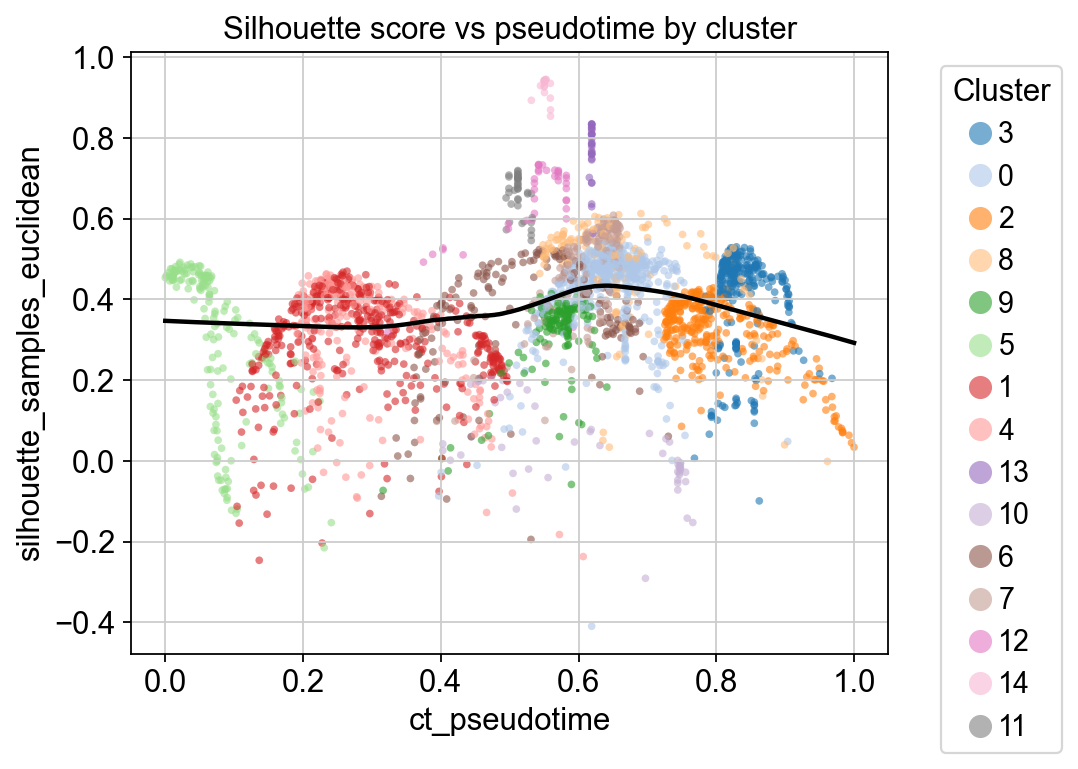

In [176]:
import seaborn as sns
import matplotlib.pyplot as plt

# include cluster column
df = adata.obs[["silhouette_samples_euclidean","ct_pseudotime","clusters"]].dropna()
df["clusters"] = df["clusters"].astype(str)  # categorical for color mapping

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df, x="ct_pseudotime", y="silhouette_samples_euclidean",
    hue="clusters", palette="tab20", s=12, alpha=0.6, linewidth=0
)

# optionally: add overall lowess smoother
sns.regplot(
    data=df, x="ct_pseudotime", y="silhouette_samples_euclidean",
    scatter=False, lowess=True, color="black", line_kws={"lw":2}
)

plt.title("Silhouette score vs pseudotime by cluster")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Cluster", markerscale=3)
plt.tight_layout()
plt.show()


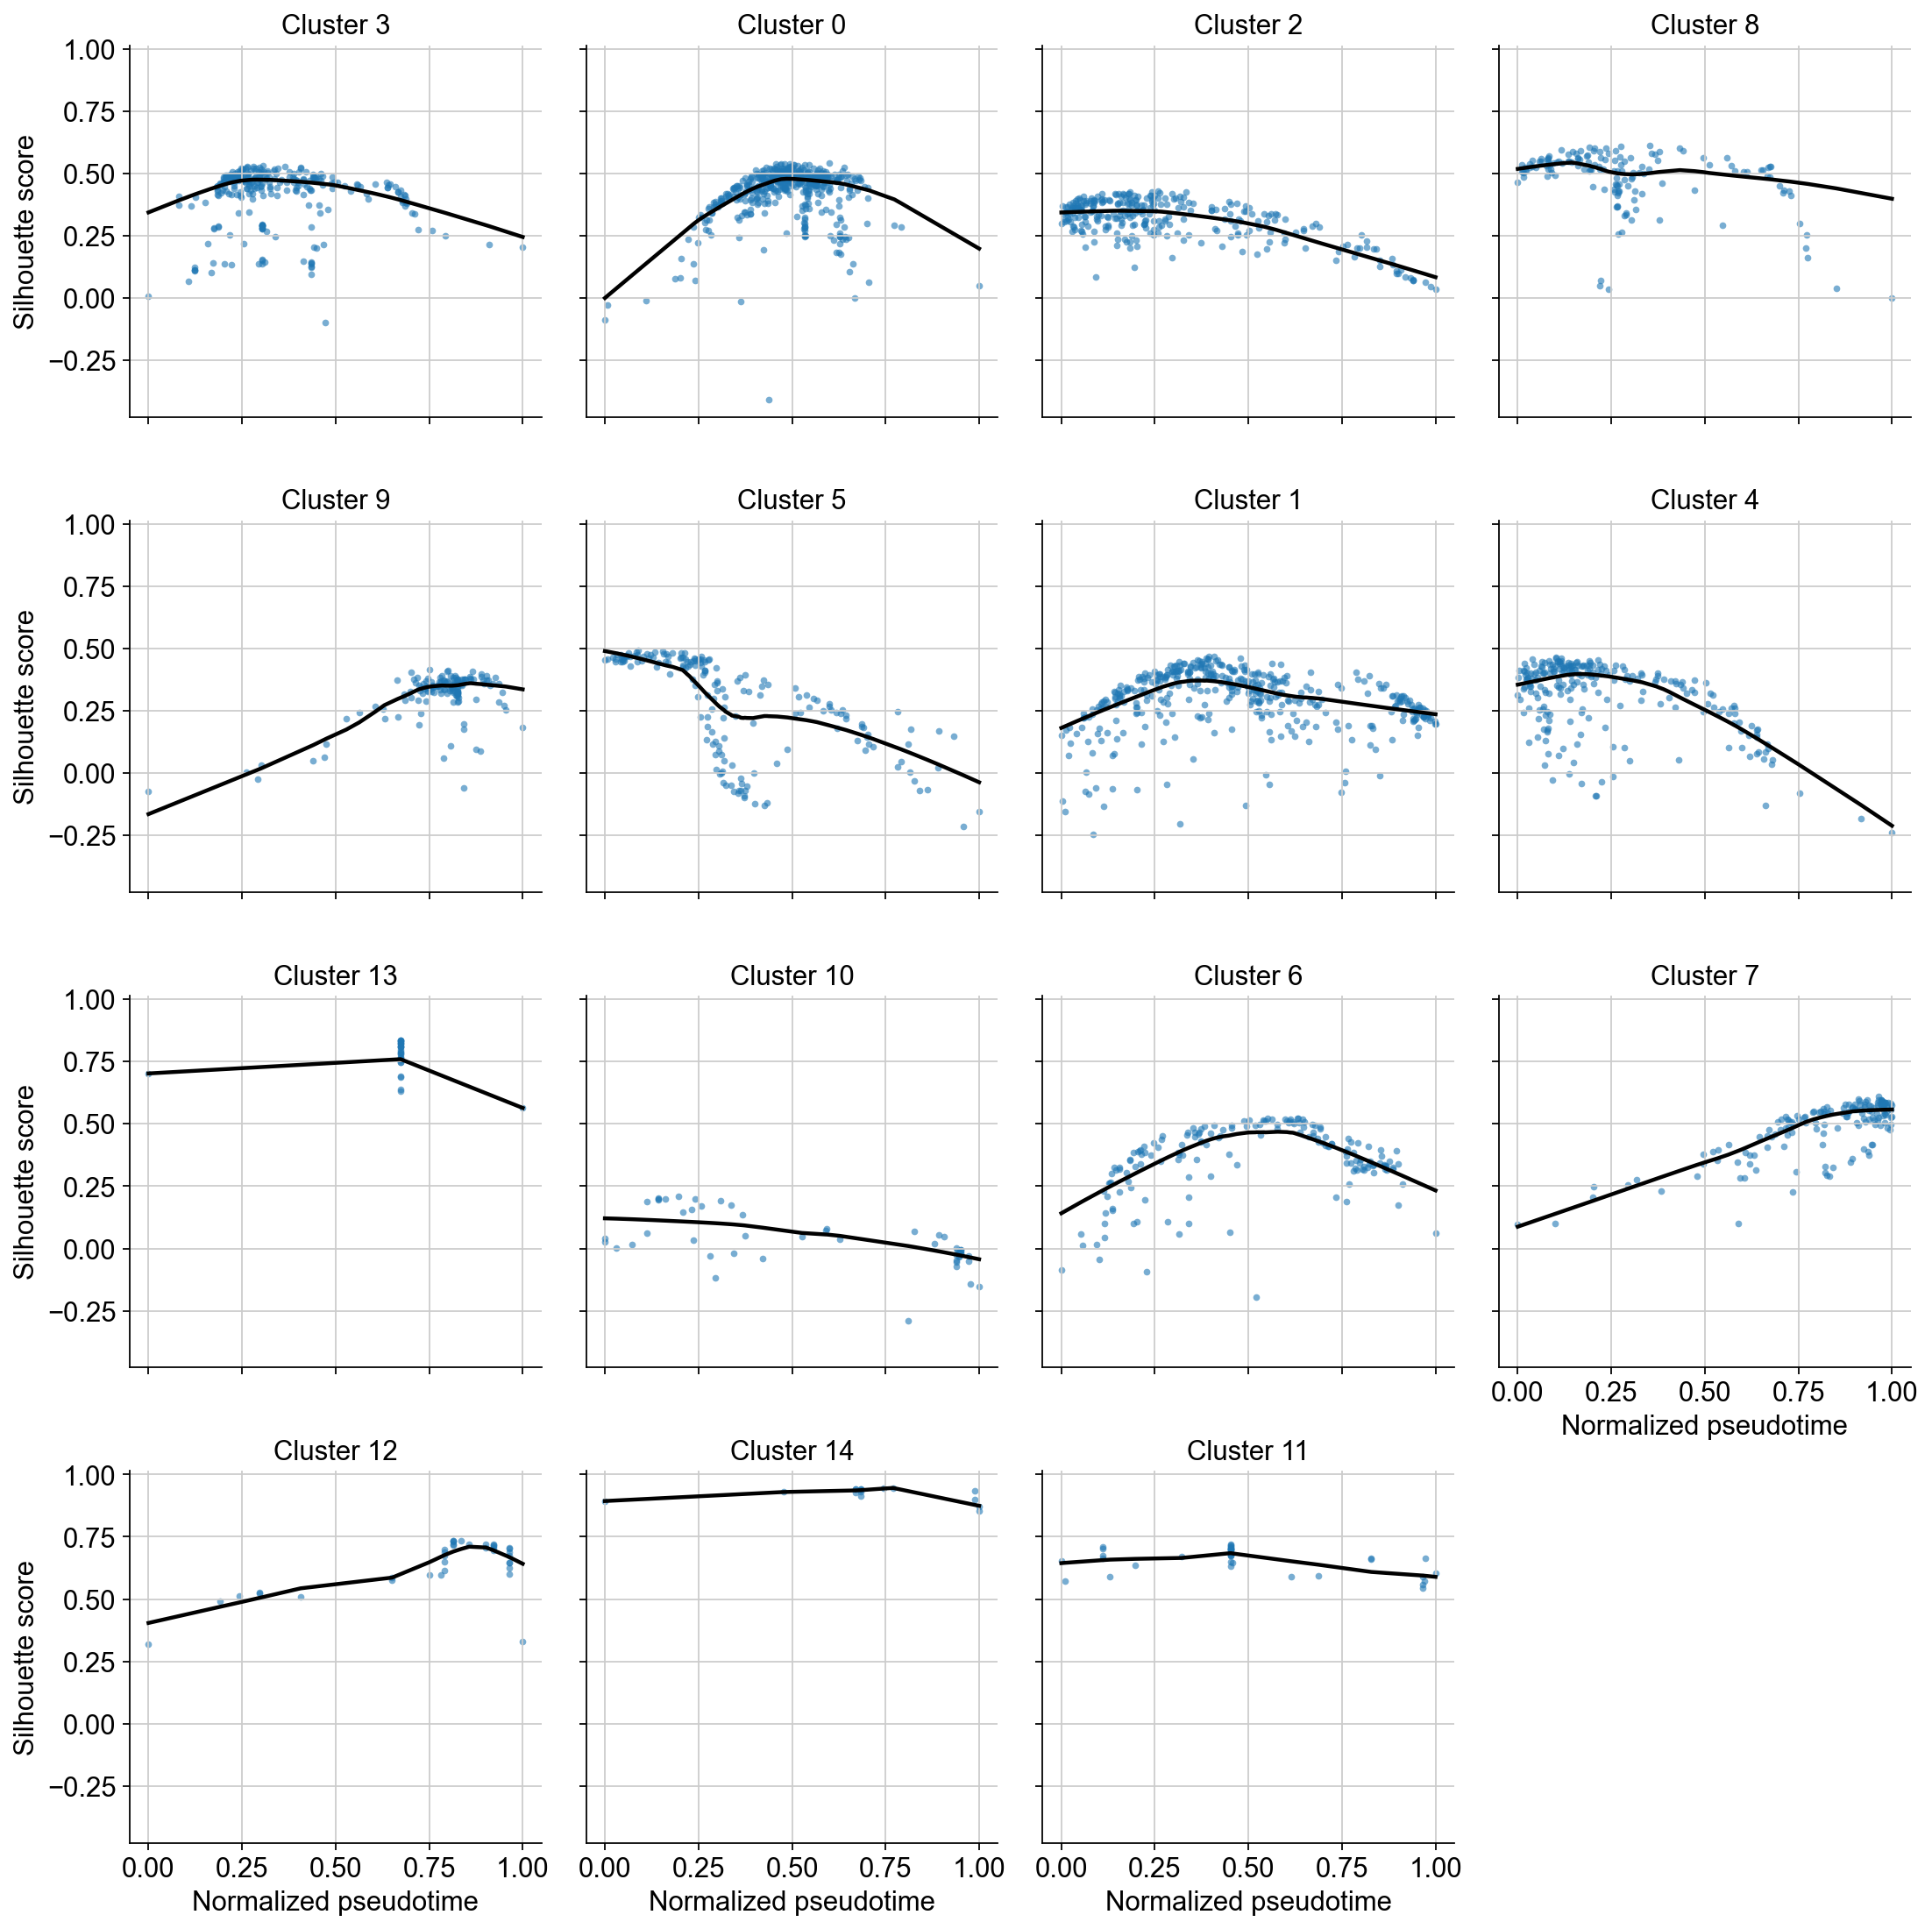

In [193]:
import seaborn as sns
import matplotlib.pyplot as plt

# prepare data
df = adata.obs[["silhouette_samples_euclidean","ct_pseudotime","clusters"]].dropna()
df["clusters"] = df["clusters"].astype(str)

# normalize ct_pseudotime within each cluster to [0,1]
df["ct_pseudotime_norm"] = df.groupby("clusters")["ct_pseudotime"].transform(
    lambda x: (x - x.min()) / (x.max() - x.min())
)

# facet by cluster
g = sns.FacetGrid(
    df, col="clusters", col_wrap=4, sharex=True, sharey=True,
    height=3.5
)
g.map_dataframe(
    sns.scatterplot,
    x="ct_pseudotime_norm", y="silhouette_samples_euclidean",
    color="tab:blue", s=12, alpha=0.6, linewidth=0
)

# add smoother inside each facet
g.map_dataframe(
    sns.regplot,
    x="ct_pseudotime_norm", y="silhouette_samples_euclidean",
    scatter=False, lowess=True, color="black", line_kws={"lw":2}
)

g.set_titles("Cluster {col_name}")
g.set_axis_labels("Normalized pseudotime", "Silhouette score")
plt.tight_layout()
plt.show()


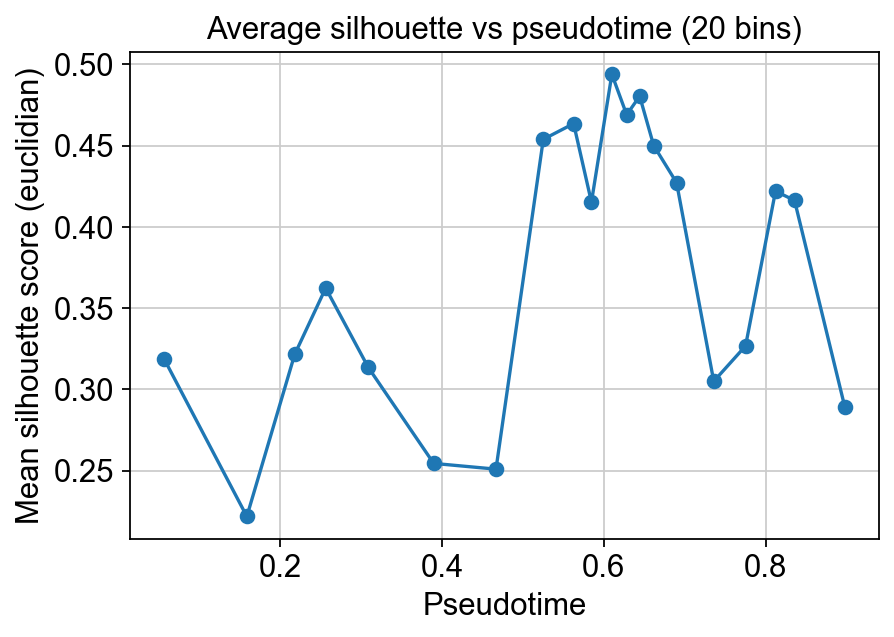

In [163]:
import numpy as np

df["bin"] = pd.qcut(df["ct_pseudotime"], q=20, labels=False)
avg = df.groupby("bin")[["ct_pseudotime","silhouette_samples_euclidean"]].mean()

plt.figure(figsize=(6,4))
plt.plot(avg["ct_pseudotime"], avg["silhouette_samples_euclidean"], marker="o")
plt.xlabel("Pseudotime")
plt.ylabel("Mean silhouette score (euclidian)")
plt.title("Average silhouette vs pseudotime (20 bins)")
plt.show()


In [178]:
from sklearn.preprocessing import MinMaxScaler

for term in ["terminalA", "terminalB"]:  # replace with your cluster labels
    mask = adata.obs["ct_pseudotime"] == term
    scaler = MinMaxScaler()
    adata.obs.loc[mask, f"{term}_pseudotime_scaled"] = scaler.fit_transform(
        adata.obs.loc[mask, ["ct_pseudotime"]]
    )


ValueError: Found array with 0 sample(s) (shape=(0, 1)) while a minimum of 1 is required by MinMaxScaler.

In [181]:
adata.obs

,n_genes_by_counts,total_counts,clusters,ct_score,ct_pseudotime,ct_num_exp_genes,silhouette_samples,silhouette_score,silhouette_samples_cityblock,silhouette_score_cityblock,...,silhouette_samples_euclidean,silhouette_score_euclidean,silhouette_samples_l1,silhouette_score_l1,silhouette_samples_l2,silhouette_score_l2,silhouette_samples_manhattan,silhouette_score_manhattan,silhouette_samples_nan_euclidean,silhouette_score_nan_euclidean
AAACCCAAGGACAGCT-1,259,740.00000,3,0.18607,0.81393,1087,0.46510,0.37297,0.37178,0.20874,...,0.46510,0.37297,0.37178,0.20874,0.46510,0.37297,0.37178,0.20874,0.46510,0.37297
AAACCCAAGGGTTTCT-1,1049,2118.00000,0,0.36673,0.63327,4256,0.48878,0.37297,0.23821,0.20874,...,0.48878,0.37297,0.23821,0.20874,0.48878,0.37297,0.23821,0.20874,0.48878,0.37297
AAACCCACAAATGGTA-1,882,4172.00000,2,0.15524,0.84476,1942,0.35924,0.37297,0.25338,0.20874,...,0.35924,0.37297,0.25338,0.20874,0.35924,0.37297,0.25338,0.20874,0.35924,0.37297
AAACCCATCGAGAAGC-1,819,2078.00000,8,0.36063,0.63937,3958,0.51855,0.37297,0.25364,0.20874,...,0.51855,0.37297,0.25364,0.20874,0.51855,0.37297,0.25364,0.20874,0.51855,0.37297
AAACCCATCTTGTTAC-1,488,1972.00000,3,0.17813,0.82187,1190,0.34320,0.37297,0.23805,0.20874,...,0.34320,0.37297,0.23805,0.20874,0.34320,0.37297,0.23805,0.20874,0.34320,0.37297
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGTTGTGATGAAT-1,1997,5387.00000,6,0.39831,0.60169,4212,0.48702,0.37297,0.25030,0.20874,...,0.48702,0.37297,0.25030,0.20874,0.48702,0.37297,0.25030,0.20874,0.48702,0.37297
TTTGGTTGTTATAGCC-1,800,1603.00000,4,0.77019,0.22981,7281,-0.02848,0.37297,0.01390,0.20874,...,-0.02848,0.37297,0.01390,0.20874,-0.02848,0.37297,0.01390,0.20874,-0.02848,0.37297
TTTGTTGAGAGAGTGA-1,177,557.00000,3,0.18569,0.81431,1073,0.49375,0.37297,0.40799,0.20874,...,0.49375,0.37297,0.40799,0.20874,0.49375,0.37297,0.40799,0.20874,0.49375,0.37297
TTTGTTGAGAGGTCGT-1,1092,1974.00000,4,0.79834,0.20166,8087,0.40287,0.37297,0.21319,0.20874,...,0.40287,0.37297,0.21319,0.20874,0.40287,0.37297,0.21319,0.20874,0.40287,0.37297


In [186]:
import scvelo as scv
import cellrank as cr
import cellrank.kernels as ck
import cellrank.estimators as cr_tl

# scVelo: compute RNA velocity (needs spliced/unspliced)
# scv.pp.filter_and_normalize(adata, n_top_genes=2000)
scv.pp.moments(adata)
scv.tl.recover_dynamics(adata)
scv.tl.velocity(adata, mode="dynamical")
scv.tl.velocity_graph(adata)

ERROR! Session/line number was not unique in database. History logging moved to new session 309
computing moments based on connectivities
    finished (0:00:07) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/8 cores)
    finished (1:02:26) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:32) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/8 cores)
    finished (0:00:54) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


In [189]:
# CellRank: build directed Markov chain; make terminals absorbing
vk  = ck.VelocityKernel(adata).compute_transition_matrix()
ckn = ck.ConnectivityKernel(adata).compute_transition_matrix()
K   = 0.8*vk + 0.2*ckn

g = cr_tl.GPCCA(K)
g.compute_schur(n_components=20)
g.identify_metastable_states()           # finds initials/terminals
g.compute_absorption_probabilities()     # fate probs per cell (directed)

cr.pl.cluster_fates(g, mode="paga_pie", clusters="clusters")

TypeError: assert_array_equal() got an unexpected keyword argument 'x'

In [222]:
cr.pl.cluster_fates(g, mode="paga_pie", clusters="clusters")

AttributeError: module 'cellrank.pl' has no attribute 'cluster_fates'

In [196]:
# directed transitions from pseudotime (no RNA velocity needed)
pk = ck.PseudotimeKernel(adata, time_key="ct_pseudotime").compute_transition_matrix()

g = cr_tl.GPCCA(pk)
g.compute_schur(n_components=20)
#g.identify_metastable_states()
g.compute_macrostates()
g.predict_terminal_states()

100%|██████████| 9/9 [08:08<00:00, 54.24s/]


ValueError: `300` value(s) are negative. Try decreasing the tolerance as `tol=...`, specifying a preconditioner as `preconditioner=...` or use a direct solver as `solver='direct'` if the matrix is small.

In [197]:
g.compute_fate_probabilities(solver="direct")

100%|██████████| 9/9 [08:05<00:00, 53.90s/]


ValueError: `300` value(s) are negative. Try decreasing the tolerance as `tol=...`, specifying a preconditioner as `preconditioner=...` or use a direct solver as `solver='direct'` if the matrix is small.

In [199]:
g.compute_fate_probabilities(
    solver="gmres",          # or "lgmres"
    preconditioner="ilu",    # incomplete LU (needs SciPy’s spilu)
    tol=1e-8,                # stricter tolerance than default
)

100%|██████████| 9/9 [09:07<00:00, 60.78s/]


ValueError: `300` value(s) are negative. Try decreasing the tolerance as `tol=...`, specifying a preconditioner as `preconditioner=...` or use a direct solver as `solver='direct'` if the matrix is small.

In [204]:
import scanpy as sc
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.utils.validation import check_is_fitted
from sklearn.cluster import SpectralBiclustering, SpectralCoclustering
from sklearn.metrics import adjusted_rand_score

# starting point: adata with preprocessing done (e.g., sc.pp.normalize_total, sc.pp.log1p)
# and existing Leiden labels in adata.obs['clusters']
# 0) select informative genes (union of top markers per Leiden cluster)
sc.tl.rank_genes_groups(adata, groupby='clusters', method='wilcoxon')
top_n = 50  # per cluster
marker_sets = []
for g in adata.obs['clusters'].cat.categories:
    genes = sc.get.rank_genes_groups_df(adata, group=g).sort_values('pvals_adj').head(top_n)['names']
    marker_sets.append(set(genes))
gene_list = sorted(set.union(*marker_sets))

# 1) build cell x gene matrix on selected genes
X = adata[:, :].X
if not isinstance(X, np.ndarray):
    X = X.toarray()

# 2) scale genes (important for biclustering)
Xz = StandardScaler(with_mean=True, with_std=True).fit_transform(X)

# 3) run biclustering
# Choose number of cell modules (r) and gene modules (c).
r = 10  # try around number of Leiden clusters ± a bit
c = 10
bic = SpectralBiclustering(n_clusters=(r, c), method='log')  # 'log' works well for counts
bic.fit(Xz)

# 4) store cell-module labels and gene-module labels
adata.obs['bicluster_cell'] = pd.Categorical(bic.row_labels_.astype(str))
adata.var.loc[gene_list, 'bicluster_gene'] = bic.column_labels_.astype(int)

# 5) compare to Leiden, and visualize
ari = adjusted_rand_score(adata.obs['clusters'].astype(int), adata.obs['bicluster_cell'].astype(int))
print("ARI vs Leiden:", ari)

sc.pl.umap(adata, color=['clusters', 'bicluster_cell'])
# Inspect gene modules:
for gmod in range(c):
    genes_in_mod = [g for g, m in zip(gene_list, bic.column_labels_) if m == gmod]
    print(f"Gene module {gmod} (n={len(genes_in_mod)}):", genes_in_mod[:25])


KeyError: "['SUB4.g10391', 'SUB4.g11264', 'SUB4.g11535', 'SUB4.g11653', 'SUB4.g11664', 'SUB4.g12303', 'SUB4.g13319', 'SUB4.g14686', 'SUB4.g16645', 'SUB4.g16694', 'SUB4.g18423', 'SUB4.g18538', 'SUB4.g18556', 'SUB4.g1886', 'SUB4.g19660', 'SUB4.g2446', 'SUB4.g2784', 'SUB4.g2879', 'SUB4.g427', 'SUB4.g4526', 'SUB4.g5387', 'SUB4.g5945', 'SUB4.g6151', 'SUB4.g7321', 'SUB4.g8542', 'SUB4.g8602', 'SUB4.g906', 'SUB4.g9211', 'SUB4.g9225'] not in index"

In [206]:
from pyclustering.cluster.clique import clique
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# Assuming `adata` is your AnnData object
X = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X
X = StandardScaler().fit_transform(X)
Xpca = PCA(n_components=10, random_state=0).fit_transform(X)

# Parameters: number of grid bins (amount_intervals), density threshold
amount_intervals = 15      # how fine to split each dimension
density_threshold = 0.02   # fraction of points required in a dense unit

clq = clique(Xpca, amount_intervals, density_threshold)
clq.process()

clusters = clq.get_clusters()
noise = clq.get_noise()

# Map to labels
labels = np.full(Xpca.shape[0], -1, dtype=int)
for k, inds in enumerate(clusters):
    labels[inds] = k

adata.obs["clique_subspace"] = labels.astype(str)


OSError: dlopen(/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/pyclustering/core/64-bit/macos/libpyclustering.so, 0x0006): tried: '/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/pyclustering/core/64-bit/macos/libpyclustering.so' (mach-o file, but is an incompatible architecture (have 'x86_64', need 'arm64e' or 'arm64')), '/System/Volumes/Preboot/Cryptexes/OS/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/pyclustering/core/64-bit/macos/libpyclustering.so' (no such file), '/Users/manueleder/venvs/cell-decisions-causality/lib/python3.13/site-packages/pyclustering/core/64-bit/macos/libpyclustering.so' (mach-o file, but is an incompatible architecture (have 'x86_64', need 'arm64e' or 'arm64'))

In [221]:
import scanpy as sc
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import SpectralBiclustering, SpectralCoclustering

# 0) assume adata has been normalized/log1p; and Leiden in adata.obs['leiden']

# 1) pick informative genes (union of top markers across Leiden clusters)
sc.tl.rank_genes_groups(adata, groupby="clusters", method="wilcoxon")
top_n = 50
marker_sets = []
for g in adata.obs["clusters"].cat.categories:
    df = sc.get.rank_genes_groups_df(adata, group=g)
    marker_sets.append(set(df.sort_values("pvals_adj").head(top_n)["names"]))
genes = sorted(set().union(*marker_sets))

# 2) build matrix and z-score genes
X = adata[:, genes].X
if not isinstance(X, np.ndarray):
    X = X.toarray()
Xz = StandardScaler(with_mean=True, with_std=True).fit_transform(X)

# 3) run biclustering
r = max(6, len(adata.obs["clusters"].cat.categories))  # number of cell clusters
c = 10                                               # number of gene clusters
bic = SpectralBiclustering(n_clusters=(r, c), method="log", random_state=0)
bic.fit(Xz)

# 4) store labels
adata.obs["bicluster_cell"] = pd.Categorical(bic.row_labels_.astype(str))

# safe assignment of gene labels
gene_labels = pd.Series(bic.column_labels_, index=genes, name="bicluster_gene")
adata.var["bicluster_gene"] = gene_labels.reindex(adata.var_names).astype("Int64")


# 5) quick looks
sc.pl.umap(adata, color=["clusters", "bicluster_cell"], wspace=0.4)


[Subspace] Using 479 genes present in adata.
[Subspace] 29 genes were not found and will be skipped (e.g., ['SUB4.g10391', 'SUB4.g11264', 'SUB4.g11535', 'SUB4.g11653', 'SUB4.g11664', 'SUB4.g12303', 'SUB4.g13319', 'SUB4.g14686', 'SUB4.g16645', 'SUB4.g16694']...).


KeyError: "Values [np.str_('SUB4.g10391'), np.str_('SUB4.g11264'), np.str_('SUB4.g11535'), np.str_('SUB4.g11653'), np.str_('SUB4.g11664'), np.str_('SUB4.g12303'), np.str_('SUB4.g13319'), np.str_('SUB4.g14686'), np.str_('SUB4.g16645'), np.str_('SUB4.g16694'), np.str_('SUB4.g18423'), np.str_('SUB4.g18538'), np.str_('SUB4.g18556'), np.str_('SUB4.g1886'), np.str_('SUB4.g19660'), np.str_('SUB4.g2446'), np.str_('SUB4.g2784'), np.str_('SUB4.g2879'), np.str_('SUB4.g427'), np.str_('SUB4.g4526'), np.str_('SUB4.g5387'), np.str_('SUB4.g5945'), np.str_('SUB4.g6151'), np.str_('SUB4.g7321'), np.str_('SUB4.g8542'), np.str_('SUB4.g8602'), np.str_('SUB4.g906'), np.str_('SUB4.g9211'), np.str_('SUB4.g9225')], from [np.str_('SUB4.g10019'), np.str_('SUB4.g10026'), np.str_('SUB4.g10064'), np.str_('SUB4.g10099'), np.str_('SUB4.g10169'), np.str_('SUB4.g10265'), np.str_('SUB4.g10274'), np.str_('SUB4.g10276'), np.str_('SUB4.g10280'), np.str_('SUB4.g10299'), np.str_('SUB4.g10318'), np.str_('SUB4.g10341'), np.str_

In [212]:
# 1) pick informative genes (union of top markers across Leiden clusters)
sc.tl.rank_genes_groups(adata, groupby="clusters", method="wilcoxon")
top_n = 50
marker_sets = []
for g in adata.obs["clusters"].cat.categories:
    df = sc.get.rank_genes_groups_df(adata, group=g)
    marker_sets.append(set(df.sort_values("pvals_adj").head(top_n)["names"]))
genes = sorted(set().union(*marker_sets))

In [213]:
genes

['SUB4.g10019',
 'SUB4.g10026',
 'SUB4.g10064',
 'SUB4.g10099',
 'SUB4.g10169',
 'SUB4.g10265',
 'SUB4.g10274',
 'SUB4.g10276',
 'SUB4.g10280',
 'SUB4.g10299',
 'SUB4.g10318',
 'SUB4.g10341',
 'SUB4.g10391',
 'SUB4.g10403',
 'SUB4.g10412',
 'SUB4.g10413',
 'SUB4.g10418',
 'SUB4.g10439',
 'SUB4.g10441',
 'SUB4.g10567',
 'SUB4.g10577',
 'SUB4.g1063',
 'SUB4.g1067',
 'SUB4.g10872',
 'SUB4.g10873',
 'SUB4.g10879',
 'SUB4.g10941',
 'SUB4.g10953',
 'SUB4.g11014',
 'SUB4.g11064',
 'SUB4.g11066',
 'SUB4.g11070',
 'SUB4.g11083',
 'SUB4.g11136',
 'SUB4.g11137',
 'SUB4.g11149',
 'SUB4.g11151',
 'SUB4.g11196',
 'SUB4.g11219',
 'SUB4.g11241',
 'SUB4.g11264',
 'SUB4.g11279',
 'SUB4.g11291',
 'SUB4.g11323',
 'SUB4.g11328',
 'SUB4.g11529',
 'SUB4.g11533',
 'SUB4.g11535',
 'SUB4.g11537',
 'SUB4.g11538',
 'SUB4.g11546',
 'SUB4.g11561',
 'SUB4.g11588',
 'SUB4.g11606',
 'SUB4.g11614',
 'SUB4.g11653',
 'SUB4.g11664',
 'SUB4.g12097',
 'SUB4.g12168',
 'SUB4.g12169',
 'SUB4.g12216',
 'SUB4.g12229',
 'SUB4.g12

In [218]:
adata.obs[:, :]

InvalidIndexError: (slice(None, None, None), slice(None, None, None))

In [252]:
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.cluster import SpectralClustering
from scipy.sparse import issparse
from scipy.sparse.csgraph import laplacian as csgraph_laplacian
from scipy.sparse.linalg import eigsh

# ---- 0) inputs you set ----
transition_label = "1"   # <-- the Leiden label of your transition cluster (string)
k = 3                    # <-- number of subclusters you want (set below or use the auto-suggest code)

# ---- 1) subset the target Leiden cluster ----
mask = (adata.obs["clusters"] == transition_label)
adata_sub = adata[mask].copy()

# Optional: keep features consistent with your main pipeline
# If PCA/neighbors were computed on HVGs, keep them:
if "highly_variable" not in adata_sub.var.columns:
    # Fallback: reuse HVGs if present on the parent AnnData
    if "highly_variable" in adata.var.columns:
        hvg_names = adata.var_names[adata.var["highly_variable"]]
        adata_sub = adata_sub[:, adata_sub.var_names.isin(hvg_names)].copy()
    else:
        sc.pp.highly_variable_genes(adata_sub, n_top_genes=2000, flavor="seurat_v3")

# ---- 2) recompute neighbors on the subset (important: do this inside the cluster) ----
sc.pp.pca(adata_sub, n_comps=30, svd_solver="arpack")
sc.pp.neighbors(adata_sub, n_neighbors=15, n_pcs=30, metric="euclidean")

# We'll use the subset's *connectivity* graph as the affinity for spectral clustering
A = adata_sub.obsp["connectivities"]

# ---- (optional) suggest k via eigengap on the Laplacian ----
def suggest_k_from_eigengap(A, kmax=8):
    # small set of eigenvalues of normalized Laplacian
    L = csgraph_laplacian(A, normed=True)
    # compute the smallest (kmax+1) eigenvalues; shift-invert helps if needed
    vals, _ = eigsh(L, k=min(kmax+1, A.shape[0]-2), which="SM")
    vals = np.sort(np.real(vals))
    gaps = np.diff(vals)
    # best k is index of largest gap, but at least 2
    k_suggest = int(np.argmax(gaps[1:]) + 2) if len(gaps) > 1 else 2
    return max(2, min(k_suggest, kmax))

k_suggested = suggest_k_from_eigengap(A, kmax=8)
print(f"[Spectral] Suggested k (eigengap) = {k_suggested}")
# If you want, you can override k with k_suggested:
# k = k_suggested

# ---- 3) spectral clustering on the precomputed graph ----
spec = SpectralClustering(
    n_clusters=k,
    affinity="precomputed",    # we pass the graph directly
    assign_labels="kmeans",    # or 'discretize' (slower, sometimes crisper)
    random_state=0,
    n_init=10
)
labels_sub = spec.fit_predict(A)


[Spectral] Suggested k (eigengap) = 5


In [253]:
labels_sub

array([0, 1, 4, 1, 3, 2, 4, 4, 2, 4, 2, 4, 0, 0, 0, 1, 2, 4, 0, 4, 3, 2,
       0, 2, 4, 1, 0, 2, 1, 1, 3, 4, 0, 4, 0, 0, 2, 0, 2, 0, 3, 4, 4, 2,
       4, 1, 3, 2, 2, 4, 4, 0, 2, 4, 4, 0, 4, 0, 2, 2, 2, 0, 4, 4, 4, 4,
       4, 2, 1, 1, 4, 3, 4, 2, 1, 4, 1, 1, 1, 4, 4, 4, 2, 4, 2, 4, 2, 4,
       1, 1, 2, 2, 1, 2, 2, 0, 2, 1, 2, 0, 4, 0, 2, 4, 2, 4, 0, 0, 4, 2,
       2, 2, 1, 3, 0, 1, 0, 2, 0, 2, 3, 1, 1, 1, 4, 4, 4, 2, 1, 1, 1, 4,
       1, 2, 4, 1, 1, 2, 4, 4, 2, 2, 2, 2, 2, 2, 2, 4, 4, 4, 0, 2, 4, 4,
       1, 4, 4, 0, 4, 0, 1, 2, 1, 2, 4, 4, 1, 0, 1, 1, 4, 4, 1, 0, 1, 1,
       4, 1, 0, 2, 2, 4, 3, 2, 1, 4, 0, 1, 0, 0, 2, 1, 2, 4, 2, 0, 0, 2,
       0, 1, 2, 4, 1, 4, 4, 1, 2, 4, 0, 4, 4, 4, 2, 4, 3, 3, 2, 2, 2, 3,
       2, 1, 3, 4, 1, 2, 2, 0, 0, 4, 4, 0, 0, 4, 2, 2, 4, 0, 4, 2, 4, 1,
       1, 1, 2, 2, 2, 2, 0, 2, 1, 3, 4, 4, 2, 0, 0, 4, 1, 2, 0, 0, 3, 2,
       0, 3, 2, 2, 2, 1, 2, 2, 2, 4, 3, 2, 0, 1, 4, 4, 4, 1, 4, 0, 2, 2,
       2, 2, 2, 4, 2, 1, 1, 0, 4, 4, 4, 2, 4, 4, 0,

In [254]:
len(labels_sub)

409

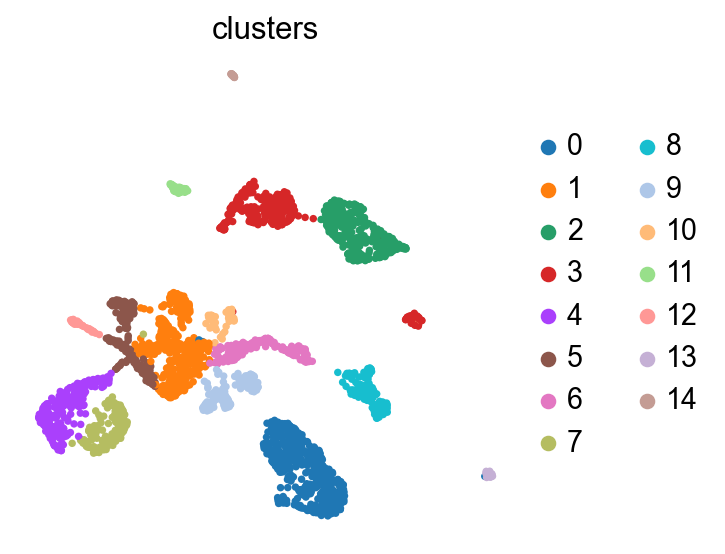

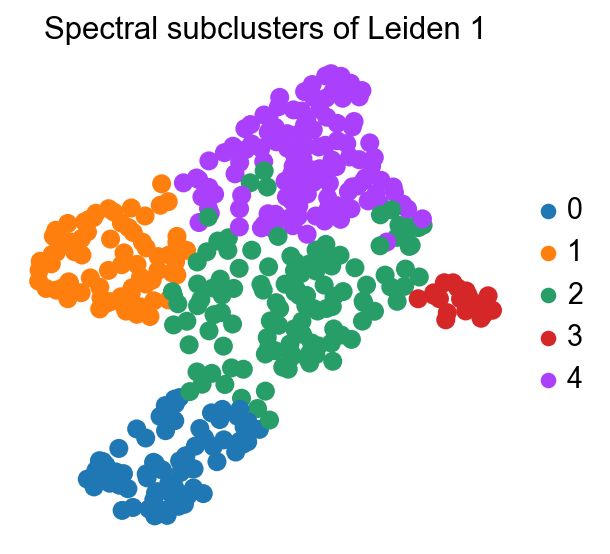

In [258]:
# ---- 4) write back to the full AnnData ----
col = f"leiden_{transition_label}_spectral{k}"
adata_sub.obs[col] = labels_sub.astype(str)

# ---- 5) quick visualization ----
# If you already have a global UMAP on adata, reuse it:
sc.pl.umap(adata, color=["clusters"], wspace=0.4)
# For a zoomed-in look on the subset only:
sc.tl.umap(adata_sub)  # computes UMAP on the subset embedding
sc.pl.umap(adata_sub, color=[col], title=f"Spectral subclusters of Leiden {transition_label}")

In [259]:
adata_sub

AnnData object with n_obs × n_vars = 409 × 20100
    obs: 'n_genes_by_counts', 'total_counts', 'clusters', 'ct_score', 'ct_pseudotime', 'ct_num_exp_genes', 'silhouette_samples', 'silhouette_score', 'silhouette_samples_cityblock', 'silhouette_score_cityblock', 'silhouette_samples_cosine', 'silhouette_score_cosine', 'silhouette_samples_euclidean', 'silhouette_score_euclidean', 'silhouette_samples_l1', 'silhouette_score_l1', 'silhouette_samples_l2', 'silhouette_score_l2', 'silhouette_samples_manhattan', 'silhouette_score_manhattan', 'silhouette_samples_nan_euclidean', 'silhouette_score_nan_euclidean', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition', 'macrostates_fwd', 'term_states_fwd', 'term_states_fwd_probs', 'bicluster_cell', 'leiden_1_spectral3', 'leiden_1_spectral5'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersion

                    count    mean  median      min     max
leiden_1_spectral5                                        
4                     121 0.34725 0.37260 -0.07562 0.46747
3                      22 0.30507 0.31816  0.13289 0.38213
2                     122 0.26794 0.31132 -0.15418 0.47013
1                      72 0.30744 0.30992  0.15056 0.43265
0                      72 0.23100 0.24987 -0.24635 0.39003


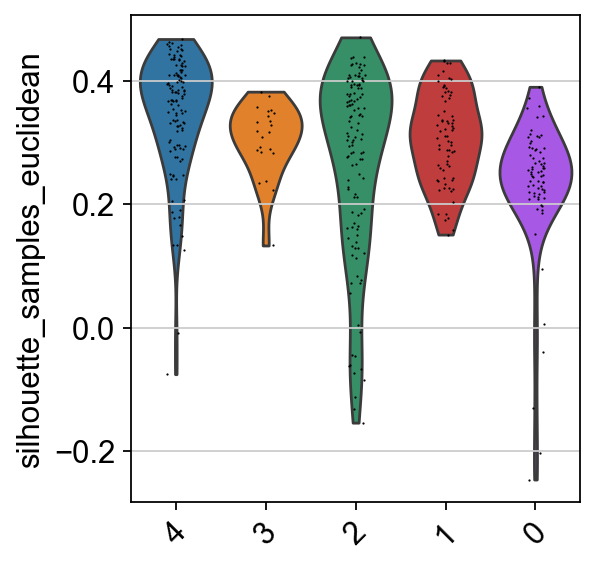

In [261]:
import numpy as np
import pandas as pd
import scanpy as sc

key = "silhouette_samples_euclidean"      # your per-cell silhouette column

# drop NaNs for clean plotting
mask = ~adata_sub.obs[key].isna()
adata_plot = adata_sub[mask].copy()

# (optional) order groups by median silhouette for nicer reading
order = (
    adata_plot.obs[[col, key]]
    .groupby(col)[key]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)
adata_plot.obs[col] = adata_plot.obs[col].cat.reorder_categories(order, ordered=True)

# quick summary table
summary = adata_plot.obs.groupby(col)[key].agg(["count","mean","median","min","max"])
print(summary)

# violin per subcluster (with jittered points)
sc.pl.violin(
    adata_plot,
    keys=key,
    groupby=col,
    stripplot=True,
    jitter=0.1,
    rotation=45
)


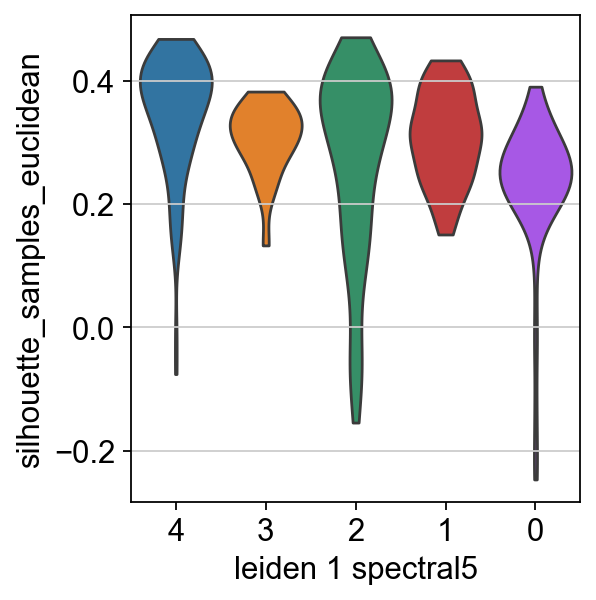

In [262]:
sc.pl.rank_genes_groups_violin  # not for this; use violin above or:
sc.pl.violin(adata_plot, keys=key, groupby=col, stripplot=False)  # simpler look